### Data Profiling

##### Importing Libraries and Loading Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json

In [2]:
df = pd.read_parquet('../data/raw/applications.parquet')

In [3]:
df.head(5)

,lpa_name,uprn,development_type,last_updated,decision,application_type,postcode,decision_process,description,borough,...,decision_date,appeal_status,valid_date,url_planning_app,lpa_app_no,centroid,appeal_decision_date,appeal_decision,id,status
0,Islington,5300000257,NaN,2025-04-03T00:00:22.289Z,Approved,All Other,N5 2BE,NaN,Single storey rear extension and extension to ...,Islington,...,NaN,NaN,28/01/2025,NaN,P2025/0271/FUL,"{""lon"": -0.093376, ""lat"": 51.552814}",NaN,NaN,Islington-P2025_0271_FUL,Withdrawn
1,Hackney,100021036707,Other listed building consents (alter-extend),2022-05-17T19:01:23.576Z,Refused,All Other,N1 4LG,Delegated,Erection of single-storey outbuilding in rear ...,Hackney,...,04/05/2022,NaN,09/03/2022,/planning/index.html?fa=getApplication&id=72883,2021/3412,"{""lon"": -7.55716, ""lat"": 49.766807}",NaN,NaN,Hackney-2021_3412,Refused
2,Hackney,10008298135,Certificates of Lawful Development,2022-05-03T19:00:11.999Z,Approved,All Other,N16 7TX,Delegated,Existing use as a self-contained dwelling (Use...,Hackney,...,19/04/2022,NaN,23/02/2022,/planning/index.html?fa=getApplication&id=72921,2021/3771,"{""lon"": -7.55716, ""lat"": 49.766807}",NaN,NaN,Hackney-2021_3771,Approved
3,Lewisham,100023677454,NaN,2022-03-15T09:30:40.668Z,NaN,All Other,NaN,NaN,The repair and waterproofing of the communal f...,Lewisham,...,NaN,NaN,01/03/2022,https://planning.lewisham.gov.uk/online-applic...,DC/22/125077,"{""lon"": 0.0016259999999999998, ""lat"": 51.461764}",NaN,NaN,Lewisham-DC_22_125077,Application Under Consideration
4,Islington,10094608174,Minor all other minor developments,2023-07-03T13:03:36.131Z,NaN,All Other,N7 0SJ,NaN,Increase in floorspace through creation of 449...,Islington,...,NaN,NaN,NaN,http://site.com/?appref=P2018/4071/FUL-or-470871,P2018/4071/FUL,"{""lon"": -0.122734, ""lat"": 51.553414}",NaN,NaN,Islington-P2018_4071_FUL,Application Received


In [4]:
df.shape

(1266689, 23)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1266689 entries, 0 to 1266688
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype
---  ------                 --------------    -----
 0   lpa_name               1266689 non-null  str  
 1   uprn                   1067591 non-null  str  
 2   development_type       522305 non-null   str  
 3   last_updated           1266689 non-null  str  
 4   decision               1176824 non-null  str  
 5   application_type       1266689 non-null  str  
 6   postcode               989184 non-null   str  
 7   decision_process       905953 non-null   str  
 8   description            1249241 non-null  str  
 9   borough                1261921 non-null  str  
 10  ward                   1187095 non-null  str  
 11  application_type_full  739653 non-null   str  
 12  decision_agency        452879 non-null   str  
 13  decision_date          1193191 non-null  str  
 14  appeal_status          5439 non-null     str  
 15  valid_dat

In [6]:
# Is 'id' different on every row? If yes, it's a primary key

print(df['id'].is_unique)

True


In [7]:
# Is the council's own reference unique on its own?

print(df['lpa_app_no'].is_unique)

False


In [8]:
# How many rows repeat the same authority + reference pair?

print(df.duplicated(['lpa_name', 'lpa_app_no']).sum())

0


##### Missing Values

In [9]:
placeholders = ["", "NULL", "Unknown", "Missing", "No description provided by LDMS"]

In [10]:
# % of real nulls and % of placeholder text, per column

missing = pd.DataFrame({
    'null_%': df.isna().mean() * 100,
    'placeholder_%': df.isin(placeholders).mean() * 100,
})

In [11]:
# Add them up and sort, worst first

missing['total_%'] = missing['null_%'] + missing['placeholder_%']
missing.round(1).sort_values('total_%', ascending=False)

,null_%,placeholder_%,total_%
appeal_status,99.6,0.0,99.6
appeal_decision_date,97.1,0.0,97.1
appeal_decision,96.6,0.0,96.6
decision_agency,64.2,0.0,64.2
url_planning_app,62.4,0.0,62.5
development_type,58.8,0.4,59.1
application_type_full,41.6,0.0,41.6
decision_process,28.5,0.3,28.8
postcode,21.9,3.5,25.4
uprn,15.7,0.0,15.7


In [12]:
# Distinct values per column

df.nunique().sort_values()

application_type               3
appeal_status                 11
decision_agency               11
decision_process              18
appeal_decision               21
lpa_name                      35
application_type_full         72
decision                     117
status                       118
borough                      173
development_type             202
ward                        2240
appeal_decision_date        7198
decision_date              13149
valid_date                 13238
postcode                  115549
url_planning_app          468197
uprn                      484909
centroid                  673023
description              1073728
last_updated             1119502
lpa_app_no               1215464
id                       1266689
dtype: int64

In [13]:
 # The 10 rarest 'borough' labels

df['borough'].value_counts().tail(10)

borough
REDBRIDGE          1
Surbiton           1
East Ham           1
Church Street      1
Colney Hatch Ln    1
Teddington         1
BRIXTON            1
Raynes Park        1
ST MARGARETS       1
Redbridge          1
Name: count, dtype: int64

##### Locations

In [14]:
# Turn each centroid's JSON text into numbers: one 'lon' and one 'lat' column

coords = pd.DataFrame(df['centroid'].map(json.loads).tolist()).astype(float)

In [15]:
# True if the point falls inside a box around Greater London

in_london = coords['lon'].between(-0.52, 0.34) & coords['lat'].between(51.28, 51.70)

In [16]:
# How many points fall outside London?

print((~in_london).sum())

102643


In [17]:
# The most common points outside London

coords[~in_london].round(2).value_counts().head(3)

lon     lat  
-7.56   49.77    101338
-15.95  90.00      1013
-6.98   51.35        23
Name: count, dtype: int64

##### Dates

In [18]:
# Parse the UK-format date text (day/month/year) into real dates; bad text becomes NaT

df['valid_dt'] = pd.to_datetime(df['valid_date'], format='%d/%m/%Y', errors='coerce')
df['decision_dt'] = pd.to_datetime(df['decision_date'], format='%d/%m/%Y', errors='coerce')
df['valid_year'] = df['valid_dt'].dt.year.astype('Int64')

In [19]:
# The snapshot date = the newest sync timestamp in the data

snapshot = pd.to_datetime(df['last_updated'], utc=True).max().tz_localize(None)
print(snapshot)

2026-07-03 01:25:17.891000


In [20]:
# Earliest and latest valid dates

print(df['valid_dt'].min(), df['valid_dt'].max())

1900-01-01 00:00:00 3034-08-30 00:00:00


In [21]:
# How many applications claim to be from after the snapshot? (impossible)

print((df['valid_dt'] > snapshot).sum())

31


In [22]:
# Days from valid to decision: median, and how many are negative (impossible)

lag_days = (df['decision_dt'] - df['valid_dt']).dt.days
print(lag_days.median())
print((lag_days < 0).sum())

56.0
851


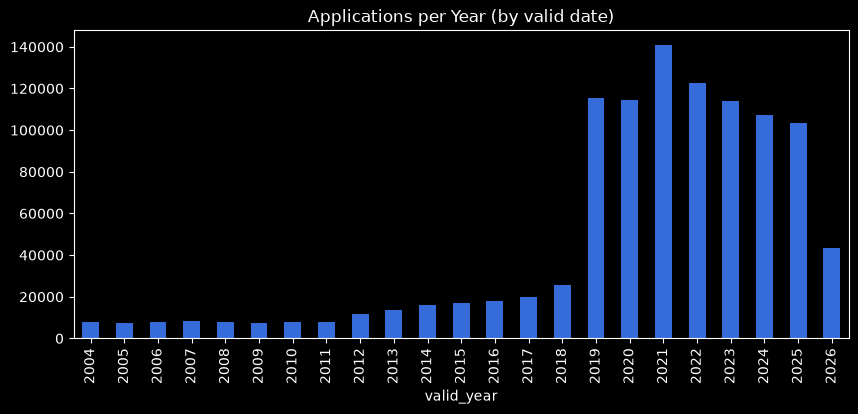

In [23]:
# Count applications per year and plot from 2004

per_year = df['valid_year'].value_counts().sort_index()
per_year.loc[2004:2026].plot(kind='bar', figsize=(10, 4), title='Applications per Year (by valid date)')
plt.show()

In [24]:
# Table of applications: one row per authority, one column per year (2015-2026)

coverage = pd.crosstab(df['lpa_name'], df['valid_year']).loc[:, 2015:2026]

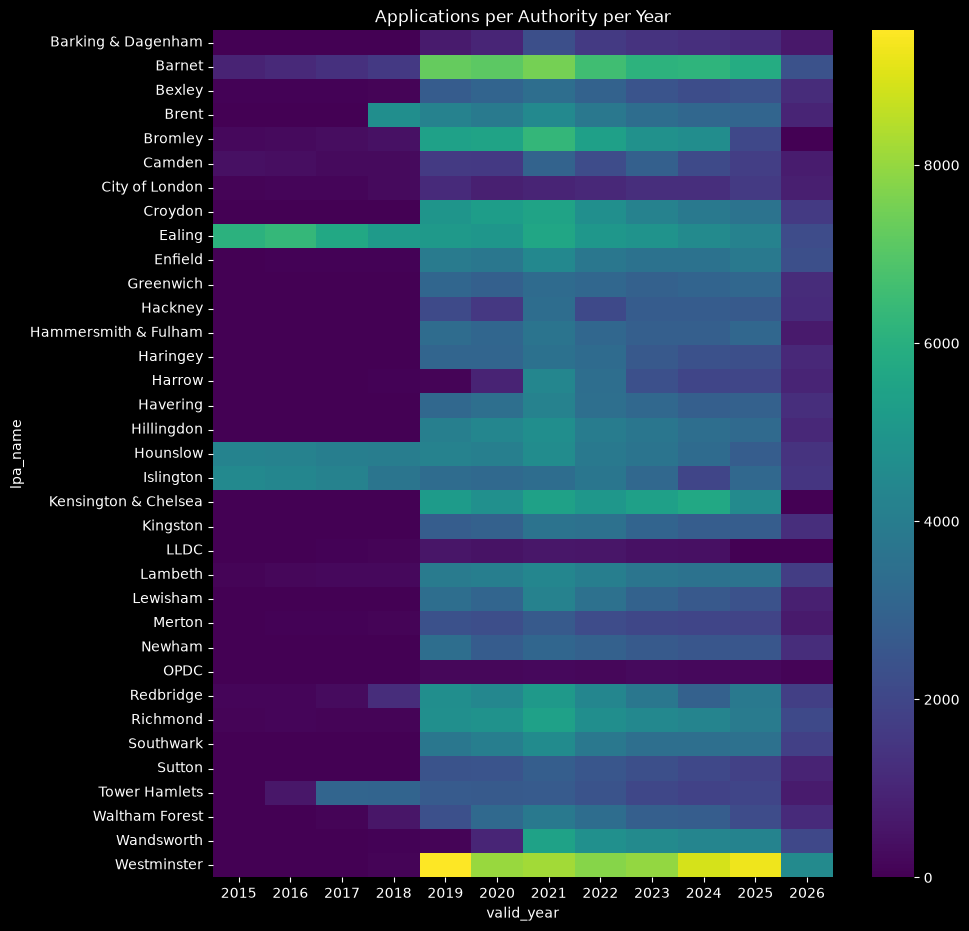

In [25]:
# Colour each cell by its count

plt.figure(figsize=(10, 11))
sns.heatmap(coverage, cmap='viridis')
plt.title('Applications per Authority per Year')
plt.show()

##### Outcomes

In [26]:
# How many different decision spellings, and the 15 most common

print(df["decision"].nunique())
df["decision"].value_counts().head(15)

117


decision
Approved                                   834494
Refused                                    152933
Withdrawn                                   61686
No Objection to Proposal (OBS only)         29517
Not Required                                28853
Comment Issued                              27298
Closed                                      13554
Unknown                                      5623
REFUSED                                      4875
Opinion Issued                               3249
Split Decision                               1782
Approve                                      1733
Objection Raised to Proposal (OBS only)      1606
PDV                                          1325
ALL DECISIONS ISSUED                         1221
Name: count, dtype: int64

In [27]:
# Rows whose decision and status are both among the main values

main = ['Approved', 'Refused', 'Withdrawn']
both = df[df['decision'].isin(main) & df['status'].isin(main + ['Completed', 'Lapsed'])]

In [28]:
# Cross-count decision (rows) against status (columns)

pd.crosstab(both['decision'], both['status'])

status,Approved,Completed,Lapsed,Refused,Withdrawn
decision,,,,,
Approved,619657,106624,38425,107,23
Refused,108,4204,530,113449,80
Withdrawn,28,25,26,0,41523


In [29]:
# True where a real decision has been recorded

has_decision = df['decision'].notna() & ~df['decision'].isin(placeholders)

In [30]:
# Applications submitted in the last 12 months before the snapshot

last_year = df['valid_dt'].between('2024-07-01', snapshot)

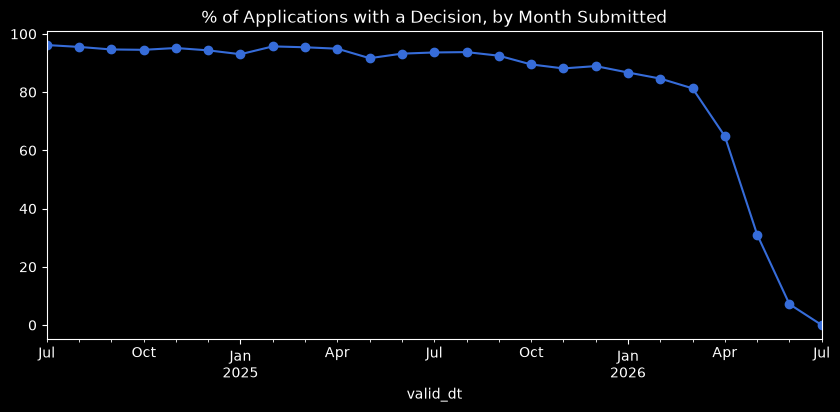

In [31]:
# % with a decision, per month submitted

pct = has_decision[last_year].groupby(df.loc[last_year, 'valid_dt'].dt.to_period('M')).mean() * 100
pct.plot(figsize=(10, 4), marker='o', title='% of Applications with a Decision, by Month Submitted')
plt.show()

In [32]:
# The modelling window: submitted from 2019 up to the snapshot

since_2019 = df[df['valid_dt'].between('2019-01-01', snapshot)]
print(len(since_2019))

861817


In [33]:
# Share of Approved vs Refused among those two outcomes

since_2019.loc[since_2019['decision'].isin(['Approved', 'Refused']), 'decision'].value_counts(normalize=True).round(3)

decision
Approved    0.821
Refused     0.179
Name: proportion, dtype: float64

##### Description Text

In [34]:
# Length of every description, in characters

length = since_2019['description'].str.len()
print(length.describe().round(0))

count    848153.0
mean        197.0
std         206.0
min           0.0
25%          84.0
50%         137.0
75%         231.0
max        4662.0
Name: description, dtype: float64


In [35]:
# How many are too short to say anything (under 20 characters)?

print((length < 20).sum())

6413


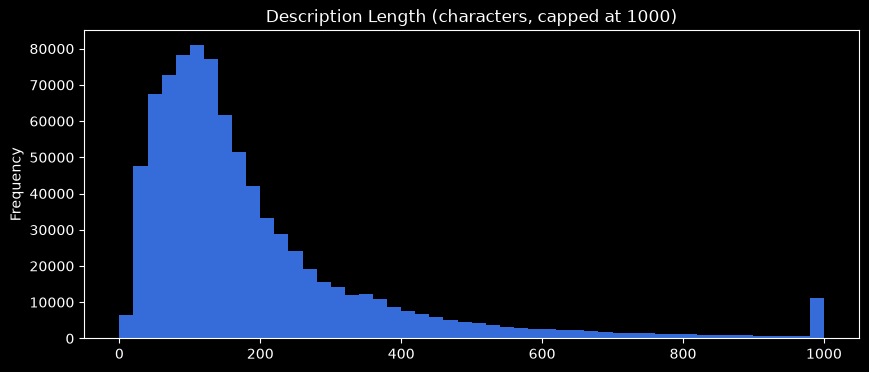

In [36]:
# Histogram of lengths, very long ones grouped at 1000

length.clip(upper=1000).plot(kind='hist', bins=50, figsize=(10, 4), title='Description Length (characters, capped at 1000)')
plt.show()

In [37]:
# Normalise text so trivial differences don't hide duplicates

text = since_2019['description'].dropna().str.lower().str.strip().str.rstrip('.')

In [38]:
# % of descriptions whose exact text appears more than once

print(text.duplicated(keep=False).mean() * 100)

20.964142082855332


In [39]:
# The most repeated descriptions

text.value_counts().head(5)

description
single storey rear extension                      7555
erection of a single storey rear extension        3280
erection of single storey rear extension          1566
construction of a single storey rear extension    1048
single storey side extension                       919
Name: count, dtype: int64

In [40]:
# % of rows with each candidate category label filled in, per authority

labels = since_2019.groupby('lpa_name')[['application_type_full', 'development_type']].agg(
    lambda s: s.notna().mean() * 100)
labels.round(0).sort_values('development_type')

,application_type_full,development_type
lpa_name,,
Barnet,67.0,0.0
Bexley,68.0,0.0
City of London,70.0,0.0
Bromley,61.0,0.0
Croydon,70.0,0.0
Greenwich,72.0,0.0
Havering,67.0,0.0
LLDC,44.0,0.0
Southwark,53.0,0.0


##### Findings and Decisions

**Data facts**
- 1,266,689 applications, 23 columns, snapshot taken 2026-07-03.
- `id` is the primary key; `lpa_name` + `lpa_app_no` is also unique.
- Most authorities only start reporting in 2019 (coverage heatmap).
- Median time from valid date to decision: 56 days.
- Since 2019, 82.1% of Approved/Refused decisions are approvals.
- 21% of descriptions are exact repeats.

**Decisions (spec for `clean.py`)**
1. **Authority:** use `lpa_name` (35 clean values). Drop `borough` (173 messy labels) and `ward`.
2. **Missing values:** convert placeholders ('', 'NULL', 'Unknown', 'Missing', 'No description provided by LDMS') to real nulls.
3. **Dates:** parse `valid_date` and `decision_date` as day/month/year. Null dates after the snapshot (31) and decision dates before the valid date (851).
4. **Locations:** parse `centroid` into `lon`/`lat`. Null any point outside the London bounding box (102,643: Cornwall and North Pole placeholders, plus a few hundred stray points).
5. **Window:** keep applications submitted from 2019-01-01 to the snapshot (861,817 rows).
6. **Outcome:** map the 117 `decision` spellings to standard outcomes. The outcome comes from `decision`, not `status` (status keeps changing after the decision).
7. **Right-censoring:** applications from spring 2026 onwards are mostly undecided, so test the outcome model only on applications old enough to have a decision.
8. **Imbalance:** 82/18 approved/refused, so judge models with PR-AUC, never accuracy.
9. **Text:** drop empty and very short descriptions (<20 characters, 6,413). Deduplicate before any train/test split, so identical texts can't sit on both sides.
10. **Classifier label:** `application_type_full` (filled for 44–91% in every authority), not `development_type` (empty for 14 of 35 authorities).
11. **Drop:** appeal fields (97–100% empty).